0.0 loss improvement over naive solution
0.0 constraint violation
0.0 loss improvement over naive solution
2.483837755346272e-16 constraint violation
0.0 loss improvement over naive solution
1.12113722928444e-16 constraint violation
0.0 loss improvement over naive solution
2.495231447213112e-16 constraint violation
0.0 loss improvement over naive solution
2.2206452925437466e-16 constraint violation
0.0 loss improvement over naive solution
8.01704901182173e-18 constraint violation
0.0 loss improvement over naive solution
3.1448640276145894e-16 constraint violation
0.0 loss improvement over naive solution
5.7681424568189845e-18 constraint violation
0.0 loss improvement over naive solution
2.4830831106075936e-16 constraint violation
2.220446049250313e-16 loss improvement over naive solution
2.220446049250313e-16 constraint violation


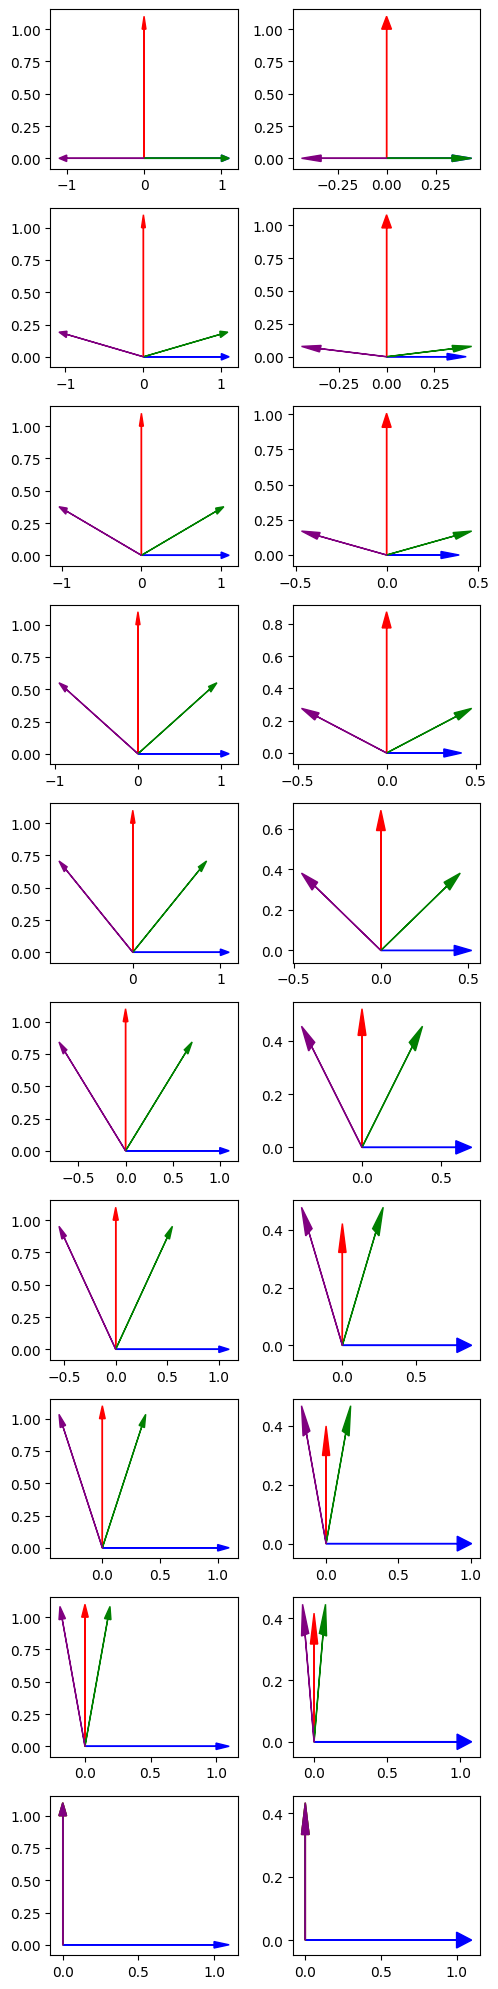

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
angles = np.linspace(0, np.pi / 2, 10)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[0,1],[np.cos(angle),np.sin(angle)], [-np.cos(angle), np.sin(angle)]]).transpose()

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print(2 - group_lasso_norm(beta), "loss improvement over naive solution")
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].arrow(0, 0, data[0,3], data[1,3], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,1].arrow(0, 0, beta[3,0], beta[3,1], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
plt.tight_layout()
plt.show()

We really want one number for the [0,1] reconstruction per feature? but that is what we have

one number overall per feature so we can't rotate... but that doesn't really make sense.  so we have this above.  negative amounts of a feature in one direction, and positive amounts in another.  why do they need to straddle?  cause when one is positive and the other negative they need to cancel out.  its the same as if one is mirrored kitty corner (multiplied by negative one in both coordinates).

Why not have two in the positive orthant? We can take the xs

0.0 loss improvement over naive solution
0.0 constraint violation
0.0 loss improvement over naive solution
4.179603653027115e-32 constraint violation
-4.2366110619695974e-13 loss improvement over naive solution
7.078648083933179e-28 constraint violation
0.0 loss improvement over naive solution
1.1102230246251565e-16 constraint violation
0.0 loss improvement over naive solution
1.1102230246251565e-16 constraint violation
0.0 loss improvement over naive solution
3.3255533430663456e-18 constraint violation
0.0 loss improvement over naive solution
2.710676960980018e-17 constraint violation
0.0 loss improvement over naive solution
2.4828383768530097e-16 constraint violation
0.0 loss improvement over naive solution
9.736282700712687e-18 constraint violation
0.0 loss improvement over naive solution
2.9548569078021244e-32 constraint violation


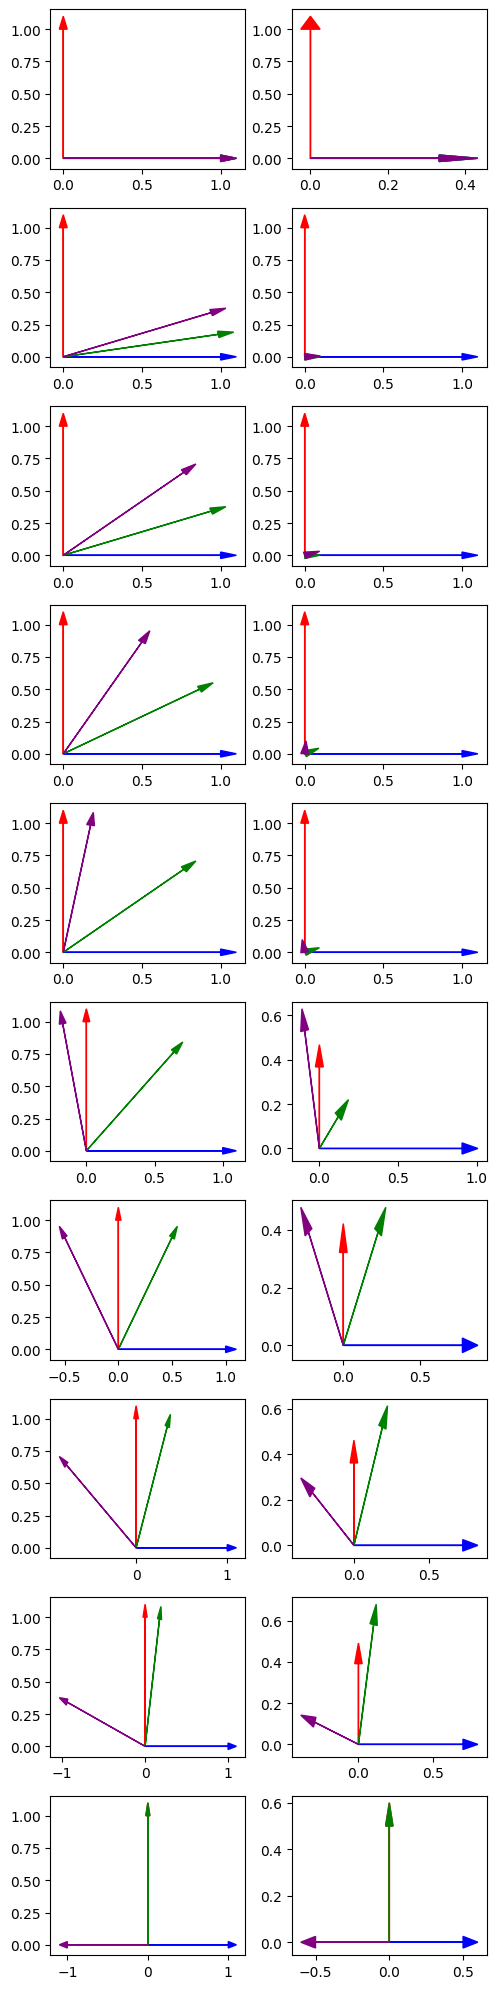

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
angles = np.linspace(0, np.pi / 2, 10)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[0,1],[np.cos(angle),np.sin(angle)], [np.cos(2*angle), np.sin(2*angle)]]).transpose()

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print(2 - group_lasso_norm(beta), "loss improvement over naive solution")
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].arrow(0, 0, data[0,3], data[1,3], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,1].arrow(0, 0, beta[3,0], beta[3,1], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
plt.tight_layout()
plt.show()

0.0 loss improvement over naive solution
0.0 constraint violation
-1.0658141036401503e-14 loss improvement over naive solution
9.615845947722612e-29 constraint violation
-4.440892098500626e-16 loss improvement over naive solution
4.441630730669687e-30 constraint violation
-6.439293542825908e-14 loss improvement over naive solution
7.939537055037721e-29 constraint violation
-4.440892098500626e-16 loss improvement over naive solution
8.097238514498273e-30 constraint violation
-8.881784197001252e-16 loss improvement over naive solution
2.563222021598464e-29 constraint violation
0.0 loss improvement over naive solution
6.1187276464479e-32 constraint violation
0.0 loss improvement over naive solution
1.1102230246251565e-16 constraint violation
-9.769962616701378e-15 loss improvement over naive solution
1.5856510843450209e-28 constraint violation
0.0 loss improvement over naive solution
1.3731157284033093e-33 constraint violation


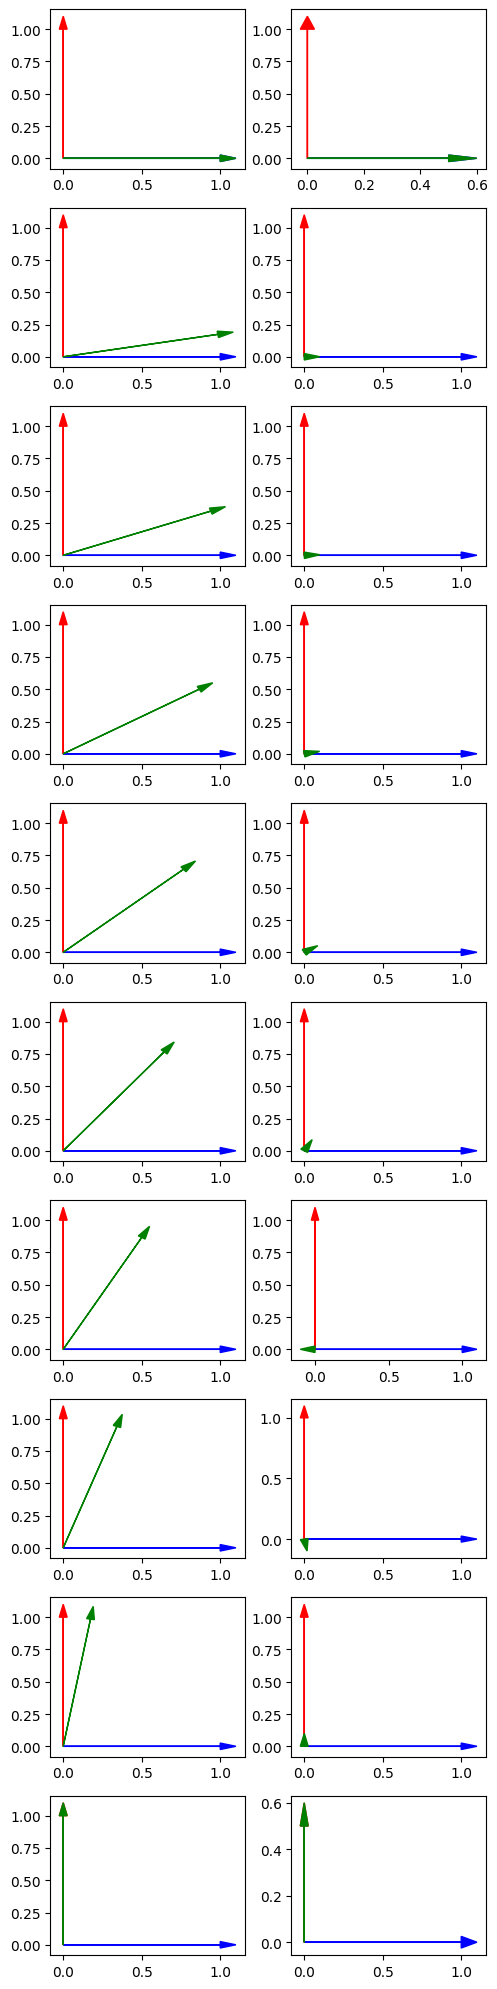

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
angles = np.linspace(0, np.pi / 2, 10)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[0,1],[np.cos(angle),np.sin(angle)], [np.cos(2*angle), np.sin(2*angle)]]).transpose()[:,[0,1,2]]

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print(2 - group_lasso_norm(beta), "loss improvement over naive solution")
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    # axes[i,0].arrow(0, 0, data[0,3], data[1,3], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    # axes[i,1].arrow(0, 0, beta[3,0], beta[3,1], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
plt.tight_layout()
plt.show()



angle 1.0471975511965976
2.0 loss
[0.66666667 0.66666667 0.66666667]
1.2318714602214022e-16 constraint violation


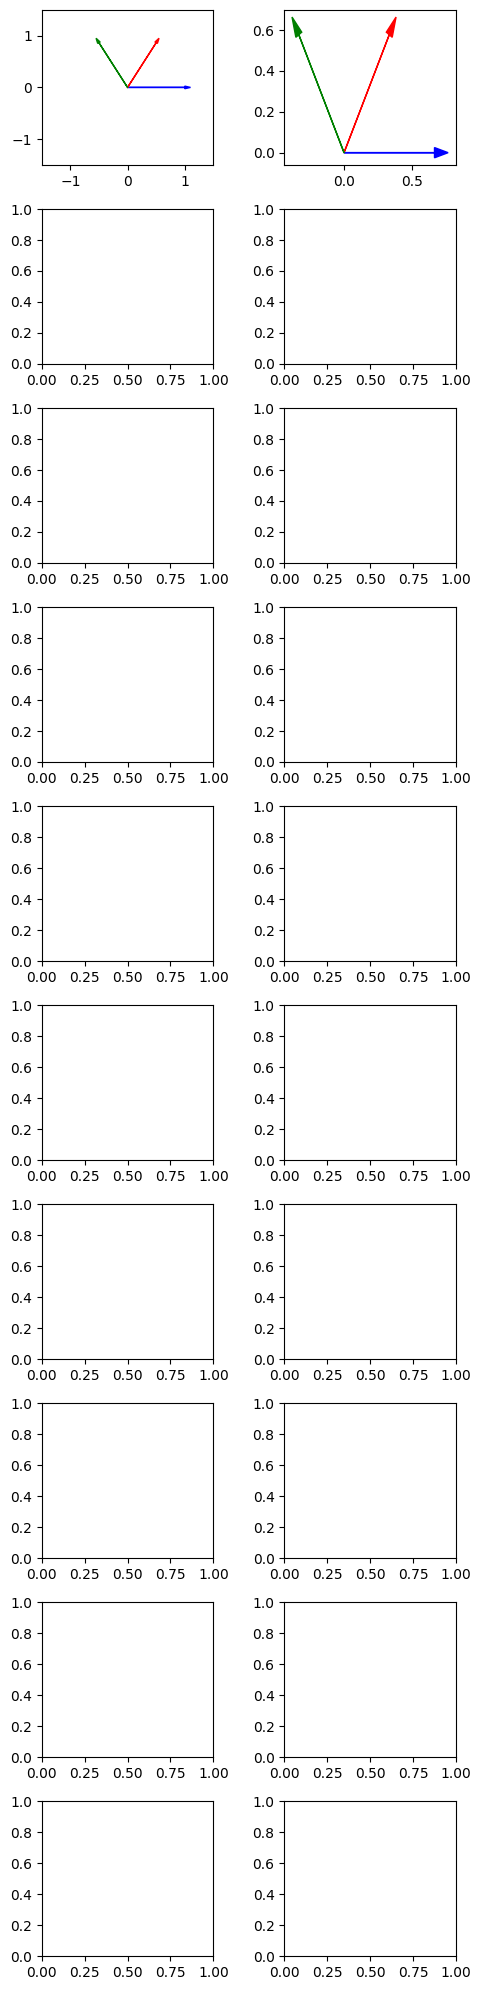

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
# angles = np.linspace(np.pi / 12, np.pi / 2, 10)
angles = np.linspace(np.pi / 3, np.pi / 3, 1)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[np.cos(angle),np.sin(angle)], [-np.cos(angle), np.sin(angle)]]).transpose()

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print('\n')
    print('angle', angle)
    print(group_lasso_norm(beta), "loss")
    print(np.linalg.norm(beta, axis = 1))
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].set_xlim([-1.5,1.5])
    axes[i,0].set_ylim([-1.5,1.5])
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].set_xlim([-1.5,1.5])
    axes[i,0].set_ylim([-1.5,1.5])
plt.tight_layout()
plt.show()

In [44]:
datas

[array([[ 1.       ,  0.5      , -0.5      ],
        [ 0.       ,  0.8660254,  0.8660254]])]

In [45]:
betas

[array([[ 6.66666667e-01,  1.98047023e-14],
        [ 3.33333333e-01,  5.77350269e-01],
        [-3.33333333e-01,  5.77350269e-01]])]

In [39]:
np.linalg.norm(betas[0], axis = 1)

array([0.66666667, 0.66666667, 0.66666667])



angle 0.2617993877991494
3.42489001858568 loss
[3.67644576e-16 1.71244501e+00 1.71244501e+00]
1.1852782987914725e-16 constraint violation


angle 0.5817764173314431
2.098259725114425 loss
[1.15243426e-16 1.04912986e+00 1.04912986e+00]
1.2418434664429946e-16 constraint violation


angle 0.9017534468637369
2.0 loss
[0.49425484 0.72676953 0.77897563]
1.6374839784140834e-16 constraint violation


angle 1.2217304763960306
2.0 loss
[0.90742523 0.46584747 0.62672731]
1.3413550435248982e-17 constraint violation


angle 1.5417075059283243
2.0008464579295566 loss
[1.00042323e+00 1.00042323e+00 3.87658124e-16]
1.5466030347969561e-18 constraint violation


angle 1.861684535460618
2.0 loss
[0.87662728 0.63112495 0.49224777]
2.98920174815427e-17 constraint violation


angle 2.181661564992912
1.9999999999999998 loss
[0.39709733 0.82190424 0.78099843]
1.1352987167582294e-16 constraint violation


angle 2.5016385945252058
2.163165383498786 loss
[2.80051229e-16 1.08158269e+00 1.08158269e+00]
1.1186438

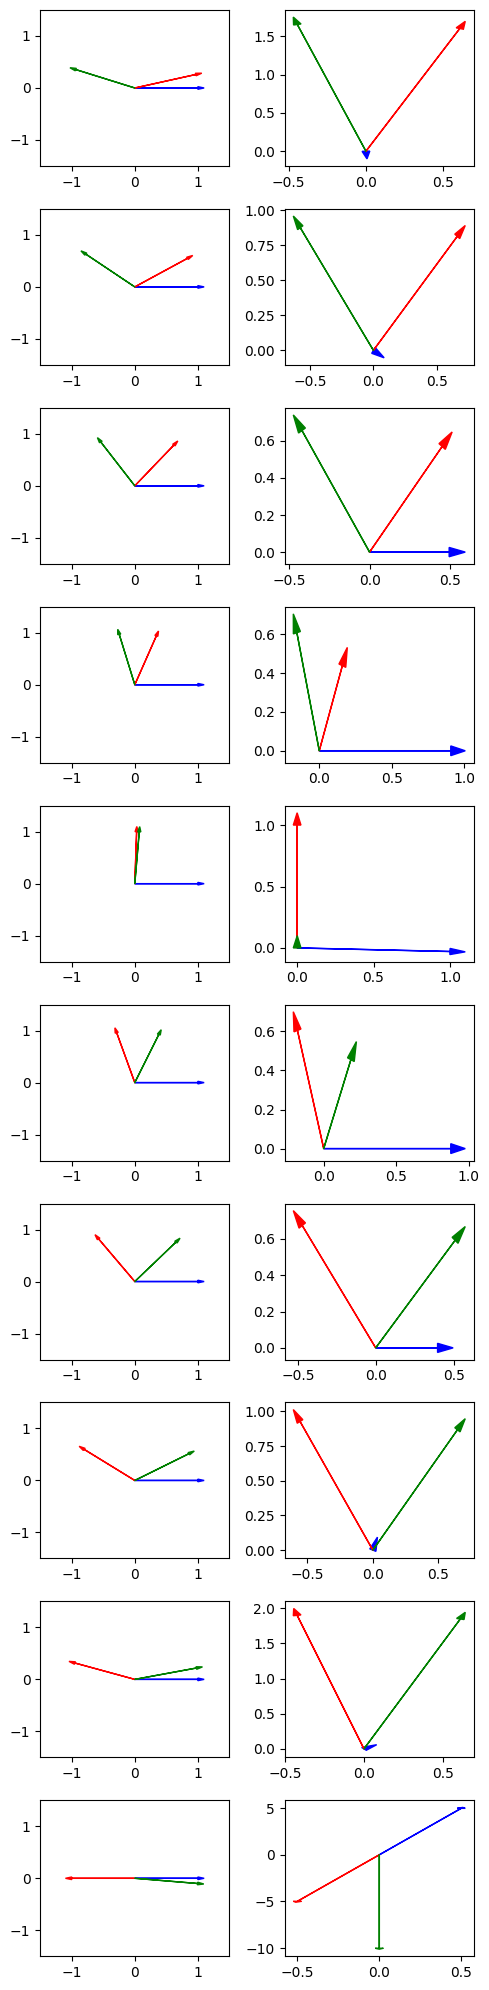

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
# angles = np.linspace(np.pi / 12, np.pi / 2, 10)
angles = np.linspace(np.pi / 12, np.pi , 10)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[np.cos(angle),np.sin(angle)], [-np.cos(angle + .1), np.sin(angle + .1)]]).transpose()

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print('\n')
    print('angle', angle)
    print(group_lasso_norm(beta), "loss")
    print(np.linalg.norm(beta, axis = 1))
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].set_xlim([-1.5,1.5])
    axes[i,0].set_ylim([-1.5,1.5])
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].set_xlim([-1.5,1.5])
    axes[i,0].set_ylim([-1.5,1.5])
plt.tight_layout()
plt.show()